# A3. 어텐션과 순환, linear attention: 긴 글을 싸게 읽는 법과 그 대가

- 영상: [28:27 Attention vs. recurrence & linear attention](https://www.youtube.com/watch?v=Vr1NzH8bT44&t=1707s) ~ 36:01 [2]
- 슬라이드: `data/lecture02.pdf` 61–91쪽 [1]
- 읽을거리: [Transformers are RNNs](https://arxiv.org/abs/2006.16236) [4] (`data/` 에 PDF)

## 목표

1. 글 길이가 늘 때 softmax 어텐션의 비용이 왜 $n^2$ 으로 느는지 그림과 숫자로 봅니다.
2. linear attention 을 두 가지 방식(한꺼번에 계산, 한 토큰씩 순환 계산)으로 짜고 결과가 같은지 확인합니다.
3. "기억할 것이 많아지면 linear attention 이 왜 헷갈리는지"를 작은 실험으로 보고, delta rule 이 무엇을 고치는지 봅니다.

**이 노트북이 답하는 질문**: softmax 어텐션은 왜 긴 글에서 비싸고, linear attention 은 그것을 어떻게 피하며, 그 대가로 무엇을 잃나?

**읽는 법**: 개념 하나마다 한 줄 정의 → 왜 필요한가 → 숫자로 따라가기 → 그림 → 그림에서 볼 것 → 식과 근거 → 직접 바꿔 보기 순서입니다.
`[4]` 같은 번호는 맨 아래 **출처** 절의 번호입니다. 이 노트북은 모델을 내려받지 않고 작은 행렬만 씁니다.

In [1]:
import math, time, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cuda.matmul.allow_tf32 = False
_ = torch.manual_seed(0)
print("device:", device)

device: cpu


In [2]:
# 그림 도구 모음입니다. 펼쳐 보지 않아도 됩니다. 본문은 draw_xxx() 를 한 줄씩 부릅니다.
# 팔레트: Okabe-Ito. 그림 안 글자는 영어로 씁니다.
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Rectangle

plt.rcParams.update({"font.size": 10, "axes.titlesize": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 100})
C = dict(orange="#E69F00", sky="#56B4E9", green="#009E73", yellow="#F0E442",
         blue="#0072B2", red="#D55E00", purple="#CC79A7", black="#000000", grey="#BBBBBB")


def _box(ax, x, y, text, w=1.6, h=0.6, fc="#FFFFFF", ec="#000000", fs=9.5):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.03", fc=fc, ec=ec, lw=1))
    ax.text(x, y, text, ha="center", va="center", fontsize=fs)


def _arrow(ax, x1, y1, x2, y2, color="#000000", rad=0.0, lw=1.0):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=12, color=color,
                                 lw=lw, connectionstyle=f"arc3,rad={rad}"))


def draw_concept_map():
    fig, ax = plt.subplots(figsize=(13, 4.0))
    _box(ax, 0, 1.5, "softmax attention\nkeeps every K, V\n(section 1)", w=2.2, h=1.0, fc=C["grey"] + "66")
    _box(ax, 3.0, 1.5, "swap exp(q.k)\nfor phi(q).phi(k)\n(section 2-1)", w=2.2, h=1.0, fc=C["sky"] + "55")
    _box(ax, 6.0, 1.5, "regroup the sums\n-> running state S\n= an RNN (2-1)", w=2.2, h=1.0, fc=C["sky"] + "55")
    _box(ax, 9.3, 2.3, "+ cost grows like n\n+ memory stays fixed\n(2-2)", w=2.4, h=1.0, fc=C["green"] + "44")
    _box(ax, 9.3, 0.7, "- fixed-size state mixes\nup items when there\nare many (3-1)", w=2.4, h=1.0, fc=C["red"] + "33")
    _box(ax, 12.3, 1.3, "fix 1: delta rule\n(overwrite, 3-2)", w=2.0, h=0.75, fc=C["orange"] + "55")
    _box(ax, 12.3, 0.1, "fix 2: hybrid models\n(a few full layers, 4)", w=2.0, h=0.75, fc=C["orange"] + "55")
    _arrow(ax, 1.1, 1.5, 1.9, 1.5); _arrow(ax, 4.1, 1.5, 4.9, 1.5)
    _arrow(ax, 7.1, 1.7, 8.1, 2.2); _arrow(ax, 7.1, 1.3, 8.1, 0.8)
    _arrow(ax, 10.5, 0.8, 11.3, 1.2); _arrow(ax, 10.5, 0.6, 11.3, 0.2)
    ax.set_xlim(-1.2, 13.5); ax.set_ylim(-0.5, 3.0); ax.axis("off")
    ax.set_title("A3 concept map: cheap attention for long text, and its price")
    plt.show()


def draw_cost_growth(d=64):
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.9), gridspec_kw={"width_ratios": [0.8, 0.8, 1.4]})
    for a, n in [(ax[0], 4), (ax[1], 8)]:
        for i in range(n):
            for j in range(n):
                a.add_patch(Rectangle((j, n - 1 - i), 1, 1, fc=(C["blue"] + "99") if j <= i else "#F2F2F2", ec="white"))
        a.set_xlim(0, n); a.set_ylim(0, n); a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([])
        a.set_title(f"n = {n} tokens:\n{n * (n + 1) // 2} pairs to score")
        a.set_xlabel("earlier token"); a.set_ylabel("current token")
    n = np.logspace(1, 5, 200)
    soft, lin = n ** 2 * d, 2 * n * d ** 2
    ax[2].loglog(n, soft, color=C["red"], lw=2, label="softmax: about n^2 x d")
    ax[2].loglog(n, lin, color=C["blue"], lw=2, label="linear: about 2 x n x d^2")
    ax[2].axvline(2 * d, ls="--", color="#777777")
    ax[2].text(2 * d * 1.2, 1e5, f"curves cross at n = 2d = {2 * d}", fontsize=9, color="#555555")
    ax[2].set_xlabel("sequence length n (log)"); ax[2].set_ylabel("multiply-adds per head (log)")
    ax[2].set_title(f"Rough operation count, d = {d}")
    ax[2].legend(fontsize=8.5, frameon=False, loc="upper left")
    fig.tight_layout(); plt.show()


def draw_rnn_vs_attention(n=5):
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
    a = ax[0]
    for t in range(n):
        x = 1.4 * t
        _box(a, x, 0, f"x{t + 1}", w=0.7, h=0.45, fc=C["grey"] + "66")
        _box(a, x, 1.3, f"h{t + 1}", w=0.9, h=0.6, fc=C["sky"] + "88")
        _arrow(a, x, 0.25, x, 0.98)
        if t:
            _arrow(a, x - 1.4 + 0.47, 1.3, x - 0.47, 1.3)
    a.text(2.8, 2.65, "state h has the SAME size at every step", ha="center", fontsize=9.5)
    a.text(2.8, -0.75, "step t needs step t-1 first -> one by one", ha="center", fontsize=9.5)
    a.set_xlim(-0.7, 6.4); a.set_ylim(-1.1, 3.0); a.axis("off"); a.set_title("A. RNN: read one token, update one state")
    b = ax[1]
    for t in range(n):
        x = 1.4 * t
        _box(b, x, 0, f"x{t + 1}", w=0.7, h=0.45, fc=C["grey"] + "66")
        _box(b, x, 1.0, f"K{t + 1},V{t + 1}", w=0.95, h=0.45, fc=C["orange"] + "66")
        _arrow(b, x, 0.25, x, 0.75)
    for t in range(n - 1):
        _arrow(b, 1.4 * (n - 1), 1.25, 1.4 * t, 1.25, color=C["red"], rad=0.35)
    b.text(2.8, 2.65, "x5 looks back at ALL stored K, V (memory grows with n)", ha="center", fontsize=9.5)
    b.text(2.8, -0.75, "during training all positions run in parallel", ha="center", fontsize=9.5)
    b.set_xlim(-0.7, 6.4); b.set_ylim(-1.1, 3.0); b.axis("off"); b.set_title("B. softmax attention: keep everything")
    fig.tight_layout(); plt.show()


def draw_running_state(phik, V):
    T = len(phik)
    fig, ax = plt.subplots(2, T, figsize=(3.0 * T, 5.4))
    S = np.zeros((phik.shape[1], V.shape[1]))
    vmax = (phik.T @ V).max()                      # 모든 칸이 같은 색 눈금을 쓰도록 최종 상태의 최댓값
    for t in range(T):
        piece = np.outer(phik[t], V[t]); S = S + piece
        for a, M, title in [(ax[0, t], piece, f"t = {t + 1}: add phi(k{t + 1}) v{t + 1}^T"),
                            (ax[1, t], S, f"state S_{t + 1} (running total)")]:
            a.imshow(M, cmap="Blues", vmin=0, vmax=vmax)
            for i in range(M.shape[0]):
                for j in range(M.shape[1]):
                    a.text(j, i, f"{M[i, j]:.1f}", ha="center", va="center", fontsize=8.5,
                           color="white" if M[i, j] > 0.6 * vmax else "black")
            a.set_xticks([]); a.set_yticks([]); a.set_title(title, fontsize=9.5)
    fig.suptitle("Linear attention keeps ONE small matrix S and adds a piece per token (it never grows)", fontsize=11)
    fig.tight_layout(); plt.show()


def draw_timing(tim):
    fig, ax = plt.subplots(figsize=(5.6, 4.2))
    ax.loglog(tim["length"], tim["softmax (ms)"], "o-", color=C["red"], label="softmax attention")
    ax.loglog(tim["length"], tim["linear (ms)"], "o-", color=C["blue"], label="linear attention")
    n0, n1 = tim["length"].iloc[0], tim["length"].iloc[-1]
    y0 = tim["softmax (ms)"].iloc[0]
    ax.loglog([n0, n1], [y0, y0 * (n1 / n0) ** 2], ls=":", color=C["red"], lw=1, label="reference slope 2 (n^2)")
    y0l = tim["linear (ms)"].iloc[0]
    ax.loglog([n0, n1], [y0l, y0l * (n1 / n0)], ls=":", color=C["blue"], lw=1, label="reference slope 1 (n)")
    ax.set_xlabel("sequence length"); ax.set_ylabel("time (ms)")
    ax.set_title("Measured time on this machine (one head, d = 64)")
    ax.legend(fontsize=8.5, frameon=False)
    fig.tight_layout(); plt.show()


def draw_memory_growth(d=64):
    n = np.logspace(2, 6, 100)
    fig, ax = plt.subplots(figsize=(5.6, 4.0))
    ax.loglog(n, 2 * n * d, color=C["red"], lw=2, label="softmax: all K and V (2 x n x d)")
    ax.loglog(n, np.full_like(n, d * d + d), color=C["blue"], lw=2, label="linear: S and z (d x d + d)")
    ax.set_xlabel("tokens read so far (log)"); ax.set_ylabel("numbers kept in memory, per head (log)")
    ax.set_title("What must be kept while writing")
    ax.legend(fontsize=8.5, frameon=False)
    fig.tight_layout(); plt.show()


def draw_orthogonal_keys():
    fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
    sets = [(ax[0], [0, 90], "A. 2 keys in 2-D: at right angles,\nno overlap (k1 . k2 = 0)"),
            (ax[1], [0, 60, 120], "B. 3 keys in 2-D: they MUST overlap\n(k1 . k2 = 0.5, k1 . k3 = -0.5)")]
    for a, angles, title in sets:
        for i, ang in enumerate(angles):
            v = np.array([np.cos(np.radians(ang)), np.sin(np.radians(ang))])
            col = [C["blue"], C["orange"], C["green"]][i]
            a.annotate("", xy=v, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=col, lw=2))
            a.text(*(v * 1.15), f"k{i + 1}", color=col, ha="center", va="center", fontsize=10)
        a.set_xlim(-1.4, 1.4); a.set_ylim(-0.4, 1.4); a.set_aspect("equal")
        a.axhline(0, color="#DDDDDD", lw=0.8, zorder=0); a.axvline(0, color="#DDDDDD", lw=0.8, zorder=0)
        a.set_title(title)
    fig.tight_layout(); plt.show()


def draw_recall(cap, d=64):
    fig, ax = plt.subplots(figsize=(5.6, 4.0))
    ax.semilogx(cap["pairs N"], cap["softmax"], "o-", color=C["red"], label="softmax (keeps all K, V)")
    ax.semilogx(cap["pairs N"], cap["linear"], "o-", color=C["blue"], label=f"linear (one {d}x{d} state)")
    ax.axvline(d, ls="--", c="gray"); ax.text(d * 1.1, 0.55, f"N = d = {d}", color="gray")
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("number of stored key-value pairs"); ax.set_ylabel("share correctly recalled")
    ax.set_title("Recall drops once N grows well past d")
    ax.legend(fontsize=8.5, frameon=False, loc="lower left")
    fig.tight_layout(); plt.show()


def draw_delta_vs_add():
    k = np.array([1.0, 0.0]); v_old = np.array([0.0, 1.0]); v_new = np.array([1.0, 0.0])
    S_add = np.outer(v_old, k) + np.outer(v_new, k)
    S_d = np.outer(v_old, k); S_d = S_d + np.outer(v_new - S_d @ k, k)
    r_add, r_d = S_add @ k, S_d @ k
    fig, ax = plt.subplots(figsize=(5.8, 4.6))
    for v, col, lab, off in [(v_old, C["grey"], "old value (0, 1)", (6, -4)), (v_new, C["blue"], "new value (1, 0)", (-10, -24)),
                             (r_add, C["orange"], f"add-only reads back ({r_add[0]:g}, {r_add[1]:g})\n= old + new, a mix", (6, 4)),
                             (r_d * 0.97 + np.array([0, 0.04]), C["green"], f"delta rule reads back ({r_d[0]:g}, {r_d[1]:g})\n= exactly the new value", (6, 10))]:
        ax.annotate("", xy=v, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=col, lw=2.2))
        ax.annotate(lab, v, textcoords="offset points", xytext=off, fontsize=9, color=col)
    ax.set_xlim(-0.3, 2.3); ax.set_ylim(-0.4, 1.5); ax.set_aspect("equal")
    ax.axhline(0, color="#DDDDDD", lw=0.8, zorder=0); ax.axvline(0, color="#DDDDDD", lw=0.8, zorder=0)
    ax.set_title("Same key k = (1, 0) written twice:\nold value first, then new value")
    fig.tight_layout(); plt.show()


def draw_update_results(upd):
    fig, ax = plt.subplots(figsize=(7.5, 3.8))
    ys = []
    for i, (_, r) in enumerate(upd.iterrows()):
        y = i
        col = C["orange"] if r["state"].startswith("linear") else C["green"]
        ax.plot([r["cos to old"], r["cos to new"]], [y, y], color="#CCCCCC", lw=2, zorder=1)
        ax.scatter(r["cos to old"], y, color=C["grey"], s=50, zorder=2)
        ax.scatter(r["cos to new"], y, color=col, s=60, zorder=3)
        ys.append(f"N = {r['pairs N']}, {r['state']}")
    ax.scatter([], [], color=C["grey"], label="similarity to OLD value")
    ax.scatter([], [], color=C["orange"], label="similarity to NEW value (add-only)")
    ax.scatter([], [], color=C["green"], label="similarity to NEW value (delta rule)")
    ax.set_yticks(range(len(ys)), ys); ax.set_xlabel("cosine similarity of what is read back")
    ax.set_xlim(-0.1, 1.05)
    ax.legend(fontsize=8.5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
    ax.set_title("After overwriting: does the state return the new value?")
    fig.tight_layout(); plt.show()


def draw_hybrid_stack(n_layers=12):
    fig, ax = plt.subplots(1, 2, figsize=(10, 4.6))
    layouts = [("A. sliding-window attention\nin every other layer", lambda i: "window" if i % 2 else "delta"),
               ("B. two global attention layers\namong delta-rule layers", lambda i: "global" if i in (3, 8) else "delta")]
    cols = {"delta": C["sky"] + "88", "window": C["purple"] + "77", "global": C["red"] + "88"}
    names = {"delta": "DeltaNet layer", "window": "sliding-window attention", "global": "global softmax attention"}
    for a, (title, kind) in zip(ax, layouts):
        for i in range(n_layers):
            k = kind(i)
            a.add_patch(Rectangle((0, i), 3, 0.85, fc=cols[k], ec="black"))
            a.text(1.5, i + 0.42, names[k], ha="center", va="center", fontsize=8.5)
        a.set_xlim(-0.2, 3.2); a.set_ylim(-0.3, n_layers + 0.2); a.axis("off"); a.set_title(title, fontsize=10)
    fig.suptitle("Two hybrid layouts tested by Yang et al. 2024 (layer count and positions are illustrative)", fontsize=10.5)
    fig.tight_layout(); plt.show()

## 0. 개념 지도

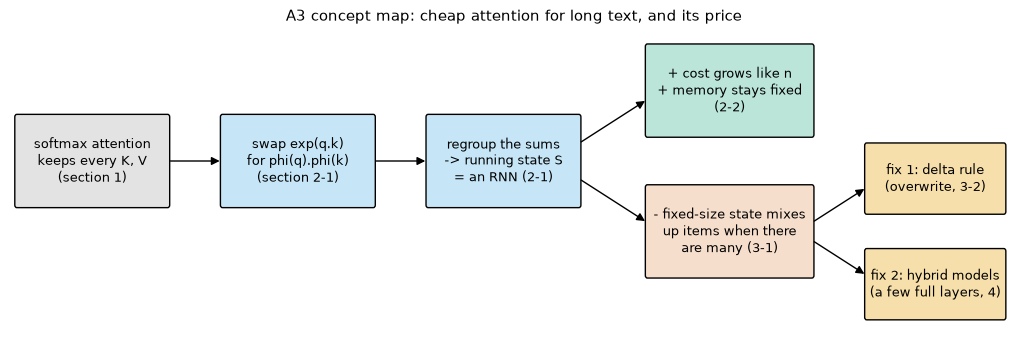

In [3]:
draw_concept_map()

**그림에서 볼 것**
- 왼쪽에서 시작합니다. softmax 어텐션은 앞 토큰의 Key, Value 를 전부 들고 있다가 매번 다 비교합니다.
- 점수 계산을 조금 바꾸면(하늘색) 같은 계산을 "작은 상태 하나를 갱신하는 RNN"으로 쓸 수 있습니다.
- 그 결과 좋은 점(초록)과 나쁜 점(빨강)이 함께 생기고, 나쁜 점을 메우는 방법 두 가지(주황)가 있습니다.

## 1. 먼저 알아 둘 것

### 1-1. $O(n^2)$ 와 $O(n)$: 비용이 늘어나는 방식

**한 줄 정의**: $O(n^2)$ 은 "글 길이 $n$ 이 두 배가 되면 계산이 약 네 배", $O(n)$ 은 "두 배가 되면 약 두 배"라는 뜻입니다.

**왜 필요한가**: softmax 어텐션은 토큰마다 앞의 모든 토큰과 점수를 매기므로 짝의 수가 $n^2$ 에 비례합니다 [3].
에이전트는 대화 기록, 도구 결과가 쌓여 글이 아주 길어지므로 이 차이가 곧 비용과 속도입니다 [1].

**숫자로 따라가기**

| 길이 $n$ | 점수 매길 짝 (앞쪽만, $n(n+1)/2$) | 길이에 비례하는 일 ($n$) |
|---|---|---|
| 4 | 10 | 4 |
| 1,000 | 500,500 | 1,000 |
| 100,000 | 약 50억 | 100,000 |

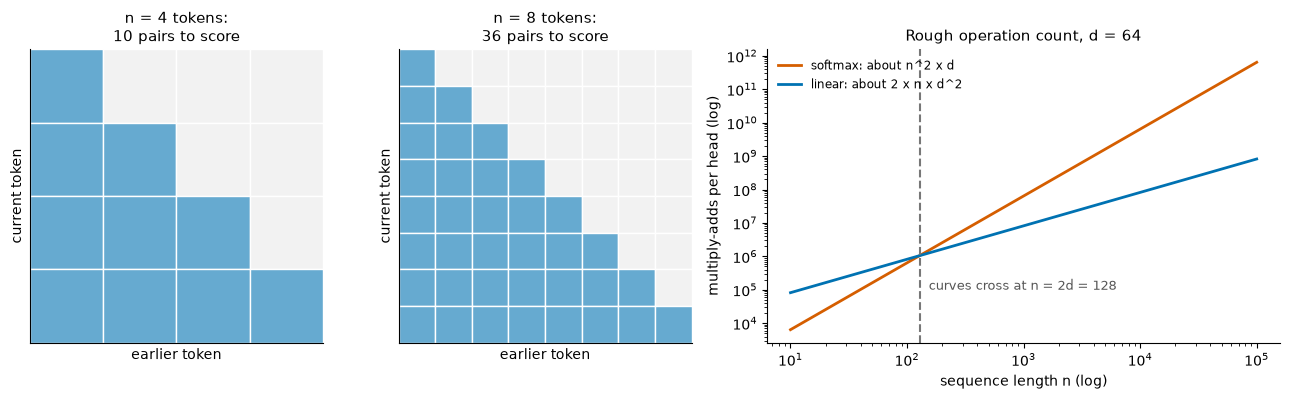

In [4]:
draw_cost_growth(d=64)

**그림에서 볼 것**
- 왼쪽 두 칸: 토큰이 4개에서 8개로 두 배가 되면, 칠해진 칸(점수 매길 짝)은 10개에서 36개로 약 네 배가 됩니다.
- 오른쪽: head 하나의 대략적인 곱셈 수입니다. 빨간 선(softmax)은 기울기 2, 파란 선(linear)은 기울기 1 입니다. 짧은 글에서는 linear 쪽이 오히려 많고, 길이가 $2d$ 를 넘으면 순위가 바뀝니다.
  (곱셈 수 식은 이 노트북에서 어림한 것입니다. 실제 시간은 2-2 에서 잽니다.)

**식과 근거**: Vaswani 등 표 1 은 층 하나의 계산량을 self-attention $O(n^2 \cdot d)$, 순환층 $O(n \cdot d^2)$ 로 적습니다 [3]. 슬라이드 61쪽도 이 표를 인용하며 "$O(n^2)$ 이라 긴 글이 비싸다"고 정리합니다 [1].

### 1-2. RNN 과 상태

**한 줄 정의**: **RNN**(순환 신경망)은 토큰을 하나씩 읽으며, 크기가 정해진 **상태**(state) $h$ 를 $h_t = f(h_{t-1}, x_t)$ 처럼 갱신합니다.

**왜 필요한가**: 슬라이드 25쪽의 언어 모델 역사에서 RNN 언어 모델(2010)과 LSTM 은 트랜스포머 앞 단계로 나옵니다 [1]. 상태 크기가 늘 같아서 글을 쓸 때 기억이 일정하다는 장점이 있습니다.
대신 $t$ 번째 계산은 $t-1$ 번째가 끝나야 할 수 있어서, 학습 때 위치들을 한꺼번에(병렬로) 계산할 수 없습니다 [3].

**숫자로 따라가기**: 토큰 5개를 읽으면 RNN 은 상태를 5번 차례로 고칩니다. 어텐션은 5번째 토큰을 계산할 때 앞 4개의 Key, Value 를 모두 꺼내 봅니다.

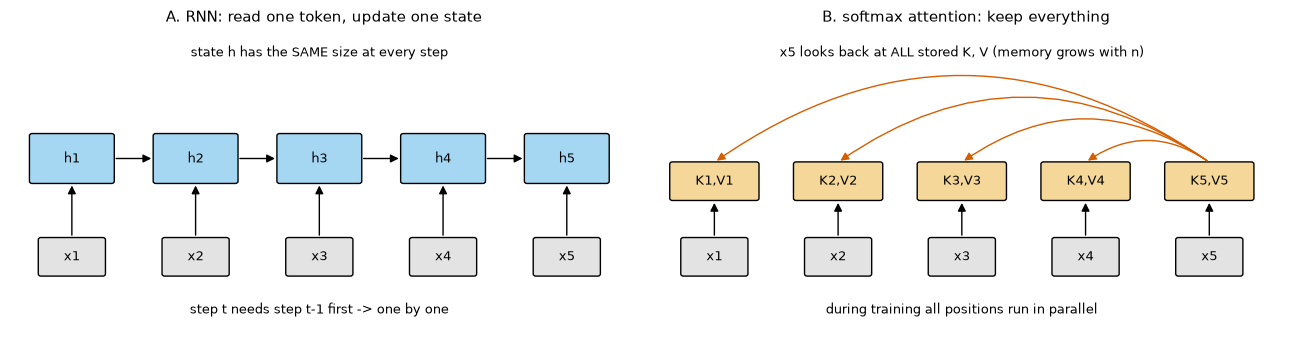

In [5]:
draw_rnn_vs_attention()

**그림에서 볼 것**
- A: 하늘색 상태 상자는 몇 번째 토큰이든 크기가 같습니다. 화살표가 한 줄로 이어져 있어 순서대로만 계산할 수 있습니다.
- B: 주황 상자(Key, Value)는 토큰마다 하나씩 쌓입니다. 빨간 화살표처럼 마지막 토큰이 앞의 모두를 봅니다.

| | RNN | softmax 어텐션 |
|---|---|---|
| 학습 때 | 앞 토큰이 끝나야 다음을 계산 (순서대로 $O(n)$ 단계) | 모든 위치를 한꺼번에 ($O(1)$ 단계) |
| 글을 쓸 때 기억 | 고정 크기 상태 하나 | 앞 토큰 전부의 Key, Value (길이에 비례) |
| 길이 $n$ 일 때 층 하나의 계산 | $O(n \cdot d^2)$ | $O(n^2 \cdot d)$ |

**식과 근거**: 표의 "순서대로 해야 하는 단계 수"와 계산량은 Vaswani 등 표 1 입니다 [3].
슬라이드 61쪽은 "순서대로 할 단계가 $O(1)$ 인 것이 GPU 병렬 학습에 아주 중요하다"고, 62쪽은 트랜스포머가 더 좋고 더 싸게 학습되었다고 설명합니다 [1].
**linear attention** 은 "학습은 병렬로, 글 쓸 때는 RNN 처럼 고정 크기 상태로" 두 장점을 다 가지려는 시도입니다 [4].

## 2. linear attention

### 2-1. 괄호를 옮기면 상태가 생긴다 (슬라이드 63–82쪽 [1])

**한 줄 정의**: softmax 어텐션의 $\exp(q \cdot k)$ 를 $\phi(q) \cdot \phi(k)$ 로 바꾼 어텐션입니다. $\phi$ 는 값을 양수로 바꾸는 함수로, 여기서는 $\text{elu}(x) + 1$ 을 씁니다 [4].
$\text{elu}(x)$ 는 $x > 0$ 이면 $x$, 아니면 $e^{x} - 1$ 입니다(PyTorch 기본값). $e^{x} - 1$ 은 늘 $-1$ 보다 크므로 $\text{elu}(x) + 1$ 은 늘 0 보다 큽니다. 점수가 음수가 되지 않게 하려는 장치입니다.

**왜 필요한가**: 이렇게 바꾸면 곱하는 순서를 바꿀 수 있습니다. $i$ 번째 출력은

$$o_i = \frac{\sum_{j \le i} \exp(q_i \cdot k_j)\, v_j}{\sum_{j \le i} \exp(q_i \cdot k_j)}
\quad \Rightarrow \quad
o_i = \frac{\phi(q_i)^\top \sum_{j \le i} \phi(k_j) v_j^\top}{\phi(q_i)^\top \sum_{j \le i} \phi(k_j)} = \frac{\phi(q_i)^\top S_i}{\phi(q_i)^\top z_i}$$

가 되고, $S_i = S_{i-1} + \phi(k_i) v_i^\top$ 처럼 **앞의 합에 한 항씩 더해 가는 상태**가 생깁니다. 이것이 RNN 꼴입니다 [4].
$S$ 는 $d \times d$ 행렬이라 글이 아무리 길어도 크기가 그대로입니다.

슬라이드는 같은 생각을 더 단순하게 보여 줍니다. 66–67쪽은 softmax 를 빼면 계산이 모두 선형이 되어 곱하는 순서를 바꿀 수 있다(K 와 V 를 먼저 곱한다)고 하고,
68–82쪽은 상태 $S_1, S_2, \dots$ 가 토큰마다 갱신되는 모습을 보여 줍니다 [1]. 슬라이드는 $\phi$ 없이 softmax 만 뺀 형태이고, 이 노트북은 Katharopoulos 등의 $\phi$ 를 넣은 형태입니다 [4].

**숫자로 따라가기**: $d = 3$ 짜리 장난감으로 토큰 4개를 읽으며 $S$ 가 어떻게 쌓이는지 봅니다.

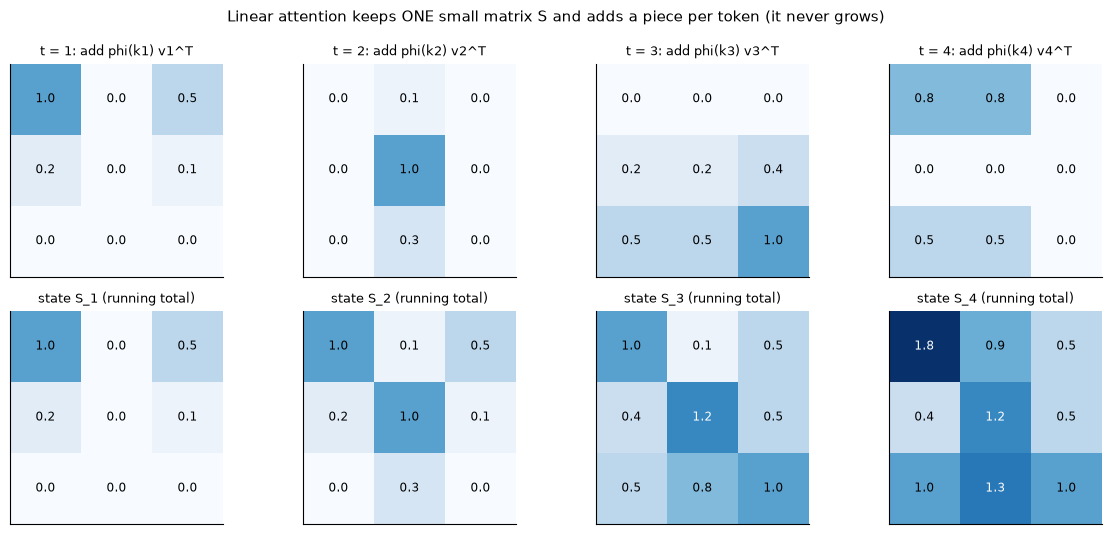

In [6]:
phik_toy = np.array([[1.0, 0.2, 0.0], [0.1, 1.0, 0.3], [0.0, 0.4, 1.0], [0.8, 0.0, 0.5]])
v_toy = np.array([[1.0, 0.0, 0.5], [0.0, 1.0, 0.0], [0.5, 0.5, 1.0], [1.0, 1.0, 0.0]])
S_check = sum(np.outer(phik_toy[t], v_toy[t]) for t in range(4))
assert np.allclose(S_check, phik_toy.T @ v_toy)        # 차례로 더한 상태 = 한꺼번에 계산한 phi(K)^T V
draw_running_state(phik_toy, v_toy)

**그림에서 볼 것**
- 위 줄: 토큰마다 $\phi(k_t) v_t^\top$ 라는 $3 \times 3$ 조각이 하나씩 생깁니다.
- 아래 줄: 상태 $S$ 는 그 조각들의 누적 합입니다. 토큰을 몇 개 읽든 $S$ 는 계속 $3 \times 3$ 입니다. 앞 토큰들을 따로 들고 있을 필요가 없습니다.
- 위 코드의 `assert` 는 "하나씩 더한 $S$"와 "한꺼번에 계산한 $\phi(K)^\top V$"가 같음을 확인합니다.

이제 두 가지 계산법을 짜고 결과가 같은지 확인합니다.

In [7]:
def phi(x):
    return F.elu(x) + 1

def linear_attn_parallel(q, k, v):
    """학습 때 방식: T x T 행렬을 만들어 한꺼번에 계산"""
    w = (phi(q) @ phi(k).T).tril()
    return (w @ v) / w.sum(-1, keepdim=True)

def linear_attn_recurrent(q, k, v):
    """글 쓸 때 방식: 고정 크기 상태 S, z 를 한 토큰씩 갱신"""
    S = torch.zeros(q.shape[1], v.shape[1], device=q.device)
    z = torch.zeros(q.shape[1], device=q.device)
    out = []
    for t in range(q.shape[0]):
        S = S + torch.outer(phi(k[t]), v[t])
        z = z + phi(k[t])
        out.append((phi(q[t]) @ S) / (phi(q[t]) @ z))
    return torch.stack(out)

T, d = 50, 16
q, k, v = torch.randn(3, T, d, device=device).unbind(0)
a_par, b_rec = linear_attn_parallel(q, k, v), linear_attn_recurrent(q, k, v)
print("최대 차이:", (a_par - b_rec).abs().max().item())
assert torch.allclose(a_par, b_rec, atol=1e-5)

최대 차이: 2.384185791015625e-07


두 방식의 결과가 같습니다. 학습할 때는 병렬 방식으로, 글을 쓸 때는 순환 방식으로 계산하면 됩니다.

병렬 방식도 $T \times T$ 행렬을 만들지 않고 **누적합**(cumulative sum)으로 계산하면 길이에 비례하는 비용으로 끝납니다 [4].
실제 구현은 글을 덩어리(chunk)로 나눠, 덩어리 안은 병렬로, 덩어리 사이는 상태로 잇는 방식도 씁니다 [6].

In [8]:
def linear_attn_cumsum(q, k, v):
    S = torch.cumsum(phi(k)[:, :, None] * v[:, None, :], dim=0)     # (T, d, d): 위치마다의 상태
    z = torch.cumsum(phi(k), dim=0)
    return torch.einsum("td,tde->te", phi(q), S) / (phi(q) * z).sum(-1, keepdim=True)

assert torch.allclose(linear_attn_cumsum(q, k, v), a_par, atol=1e-5)
print("누적합 방식도 같음")

누적합 방식도 같음


**직접 바꿔 보기**: 위에서 `T` 를 200 으로, `d` 를 4 로 바꿔도 세 방식이 같은지 확인해 보세요.

### 2-2. 길이에 따른 시간과 메모리 (슬라이드 83, 87쪽 [1])

**한 줄 정의**: 같은 일을 하는 두 어텐션의 실행 시간을 길이를 늘려 가며 잽니다. head 하나, 차원 64 입니다.

**왜 필요한가**: 1-1 의 곱셈 수는 어림이었습니다. 실제 기계에서는 행렬 곱이 아주 빠르게 처리되는 등 다른 요인이 섞입니다.
Katharopoulos 등은 아주 긴 글을 이어 쓸 때 linear attention 이 최대 4,000배 빨랐다고 보고했습니다 [4].

**숫자로 따라가기**: 아래 표가 이 노트북을 실행한 기계에서 잰 값입니다. 기계(CPU 또는 GPU)마다 숫자는 다릅니다. softmax 쪽은 $T \times T$ 점수 행렬을 실제로 만드는 단순한 구현입니다.

,length,softmax (ms),linear (ms)
0,512,0.37,6.54
1,1024,1.37,12.42
2,2048,5.16,26.31
3,4096,31.32,57.58
4,8192,143.07,182.10
5,16384,636.52,515.85


긴 쪽 기울기: softmax 2.17, linear 1.58  (2면 n^2, 1이면 n에 비례)
길이    512: 더 빠른 쪽 = softmax
길이   1024: 더 빠른 쪽 = softmax
길이   2048: 더 빠른 쪽 = softmax
길이   4096: 더 빠른 쪽 = softmax
길이   8192: 더 빠른 쪽 = softmax
길이  16384: 더 빠른 쪽 = linear
누적합 방식이 위치마다 만드는 64x64 상태 묶음의 크기 (길이 16384): 268 MB


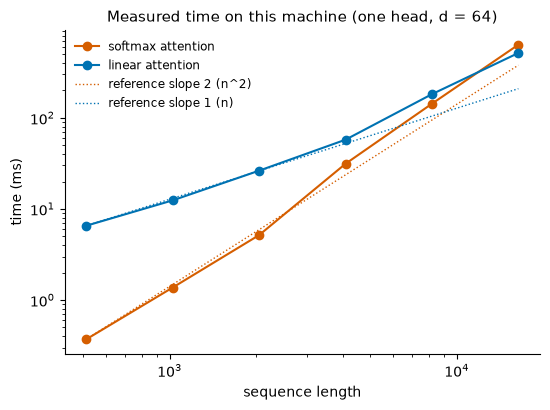

In [9]:
def softmax_attn(q, k, v):
    s = (q @ k.T) / math.sqrt(q.shape[1])
    s = s.masked_fill(torch.triu(torch.ones_like(s, dtype=torch.bool), 1), float("-inf"))
    return torch.softmax(s, -1) @ v

def timeit(fn, *args, reps=5):
    """여러 번 재서 가운데 값(중앙값)을 쓴다. 다른 작업 때문에 한 번 튀는 값을 줄인다."""
    fn(*args)
    ts = []
    for _ in range(reps):
        if device == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter(); fn(*args)
        if device == "cuda": torch.cuda.synchronize()
        ts.append(time.perf_counter() - t0)
    return float(np.median(ts))

sizes = [1024, 2048, 4096, 8192, 16384, 32768] if device == "cuda" else [512, 1024, 2048, 4096, 8192, 16384]
rows = []
for n in sizes:
    qn, kn, vn = torch.randn(3, n, 64, device=device).unbind(0)
    rows.append({"length": n, "softmax (ms)": 1e3 * timeit(softmax_attn, qn, kn, vn),
                 "linear (ms)": 1e3 * timeit(linear_attn_cumsum, qn, kn, vn)})
    del qn, kn, vn
tim = pd.DataFrame(rows).round(2)
display(tim)

big = tim.iloc[-3:]
slope = lambda col: np.polyfit(np.log(big["length"]), np.log(big[col]), 1)[0]
print(f"긴 쪽 기울기: softmax {slope('softmax (ms)'):.2f}, linear {slope('linear (ms)'):.2f}  (2면 n^2, 1이면 n에 비례)")
faster = np.where(tim["softmax (ms)"] < tim["linear (ms)"], "softmax", "linear")
for n_, f_ in zip(tim["length"], faster):
    print(f"길이 {n_:6d}: 더 빠른 쪽 = {f_}")
n_max = int(tim["length"].iloc[-1])
print(f"누적합 방식이 위치마다 만드는 64x64 상태 묶음의 크기 (길이 {n_max}): {n_max * 64 * 64 * 4 / 1e6:.0f} MB")
draw_timing(tim)

**그림에서 볼 것**
- 점선은 기울기 2(빨강)와 1(파랑)의 기준선입니다. 실제 선이 각자의 점선과 비슷한 기울기인지 보세요.
- 위에 찍힌 "더 빠른 쪽"으로, 길이에 따라 순위가 바뀌는 곳을 찾아보세요. 짧은 글에서는 행렬 곱 하나로 끝나는 softmax 가 이길 수 있습니다.
  이 노트북을 만들 때의 CPU 실행에서는 8,192 와 16,384 사이에서 순위가 바뀌었습니다. 기계마다 이 자리는 다릅니다.
- 기울기도 이 기계의 결과입니다. 짧은 길이에서는 계산보다 메모리 읽기와 고정 비용이 시간을 좌우해서 기울기가 이론값보다 낮게 나올 수 있어, 기울기는 가장 긴 세 길이로만 계산합니다.
- 반대로 linear 쪽 기울기는 1 보다 **크게** 나올 수 있습니다. 이 노트북의 누적합 구현은 위치마다 64×64 상태를 모두 만들어 두기 때문에(위 출력의 MB),
  길이가 길어질수록 계산보다 이 큰 묶음을 메모리에 쓰고 읽는 시간이 커지는 것으로 보입니다. 실제 구현은 글을 덩어리로 나눠 이 메모리를 줄입니다 [6].

글을 쓸 때 들고 있어야 하는 기억의 크기도 다릅니다. softmax 어텐션은 앞 토큰 전부의 Key 와 Value(KV 캐시, A5 에서 자세히)를, linear attention 은 상태 $S, z$ 하나를 들고 다닙니다 [1][4].

,length,"softmax: K,V numbers","linear: S,z numbers"
0,1000,128000,4160
1,10000,1280000,4160
2,100000,12800000,4160
3,1000000,128000000,4160


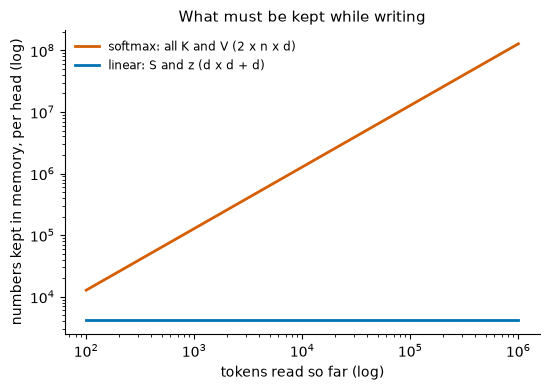

In [10]:
d = 64
display(pd.DataFrame({"length": [1_000, 10_000, 100_000, 1_000_000],
                      "softmax: K,V numbers": [2 * n * d for n in [1_000, 10_000, 100_000, 1_000_000]],
                      "linear: S,z numbers": [d * d + d] * 4}))
draw_memory_growth(d=64)

**그림에서 볼 것**: 빨간 선은 읽은 토큰 수에 비례해 올라가고, 파란 선은 평평합니다. 100만 토큰이면 head 하나에 1억 2,800만 개 대 4,160개입니다.

**식과 근거**: 슬라이드 87쪽 [1]: softmax 어텐션은 길이에 $O(n^2)$, KV 캐시(메모리)가 $O(n)$ 으로 늘고, linear attention 은 $O(n)$ 에 상태 메모리가 일정합니다.

## 3. 고정 크기 상태의 대가

### 3-1. 연상 기억과 그 용량

**한 줄 정의**: **연상 기억**(associative memory)은 이름표(key)로 내용(value)을 찾아오는 기억입니다. 어텐션도 Query 로 Key 를 찾아 Value 를 가져오는 연상 기억입니다.

**왜 필요한가**: 긴 글에서 "앞에 나온 특정 정보를 정확히 찾아오기"가 바로 이 일입니다. linear attention 은 모든 쌍을 $S = \sum_i v_i k_i^\top$ 하나에 더해 두기 때문에,
쌍이 많아지면 서로 섞입니다. Schlag 등은 이 방식의 기억 용량에 한계가 있음을 보였고 [5], Yang 등은 linear attention 이 문맥 안에서 찾아오는 일에서 softmax 어텐션보다 뒤처진다고 정리합니다 [6].

**표기 주의**: 2절에서는 상태를 $S = \sum \phi(k) v^\top$ 로 쓰고 $\phi(q)^\top S$ 로 읽었습니다. 이 절에서는 원리만 보려고 $\phi$ 를 빼고
$S = \sum v k^\top$ 로 쓰고 $S k$ 로 읽습니다. 행과 열을 바꾼(전치) 것일 뿐 같은 생각입니다.

**숫자로 따라가기**: 이름표 길이를 1 로 맞추면(아래 `make_pairs` 처럼) 찾을 때 $S k_j = v_j + \sum_{i \ne j} v_i (k_i \cdot k_j)$ 가 됩니다. 둘째 항은 다른 쌍이 섞여 들어온 잡음입니다.
이름표들이 서로 직각이면($k_i \cdot k_j = 0$) 잡음이 0 인데, $d$ 차원에서 서로 직각인 방향은 최대 $d$ 개뿐입니다. 2차원이면 2개입니다.

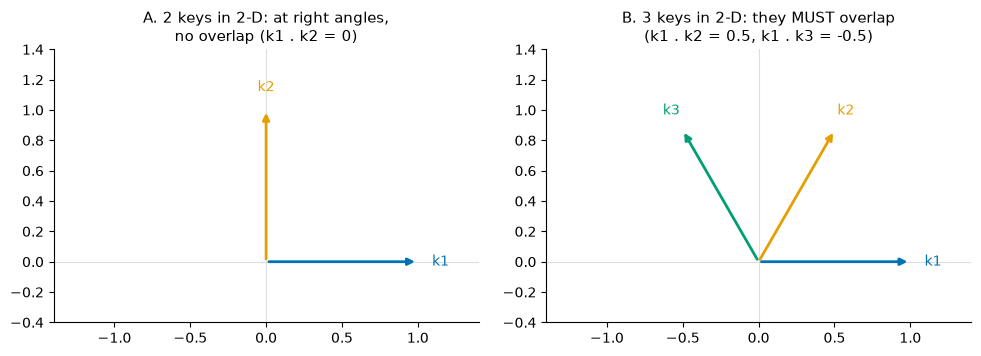

In [11]:
draw_orthogonal_keys()

**그림에서 볼 것**
- A: 2차원에 이름표 2개는 직각으로 놓을 수 있어 서로 섞이지 않습니다.
- B: 3개째부터는 어떻게 놓아도 다른 이름표와 겹칩니다(내적이 0 이 아님). 그만큼 다른 쌍의 내용이 섞여 나옵니다.

**실험.** 이름표–내용 쌍 $N$ 개를 기억시킨 뒤, 이름표로 내용을 다시 찾게 합니다. 찾아낸 벡터와 가장 비슷한 내용이 정답이면 맞힌 것으로 칩니다. $d = 64$ 입니다.

- **softmax 기억**: 쌍을 전부 그대로 들고 있다가, 이름표가 가장 비슷한 쌍에 가중치를 몰아줍니다(KV 캐시와 같은 방식).
- **linear 기억**: 모든 쌍을 $S$ 하나에 더해 둡니다. 원리를 보려고 $\phi$ 와 나누기는 뺐습니다.

,pairs N,softmax,linear
0,16,1.0,1.000000
1,32,1.0,1.000000
2,64,1.0,1.000000
3,128,1.0,0.984375
4,256,1.0,0.769531
5,512,1.0,0.341797
6,1024,1.0,0.106445


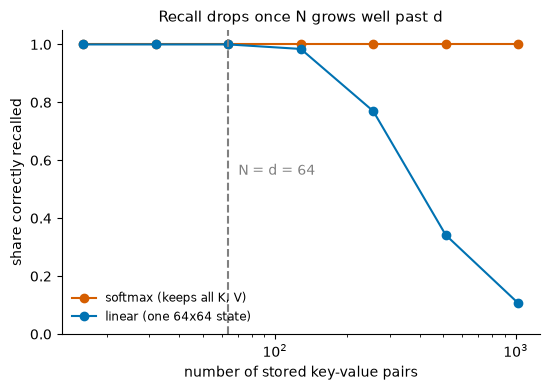

In [12]:
def make_pairs(N, d=64, seed=0):
    g = torch.Generator().manual_seed(seed)
    K = F.normalize(torch.randn(N, d, generator=g), dim=-1)
    V = F.normalize(torch.randn(N, d, generator=g), dim=-1)
    return K, V

def recall(K, V, R):
    """찾아낸 벡터 R 이 정답 내용과 가장 비슷하면 맞힌 것"""
    return ((F.normalize(R, dim=-1) @ V.T).argmax(-1) == torch.arange(len(K))).float().mean().item()

def read_softmax(K, V, Q, beta=30.0):
    return torch.softmax(beta * Q @ K.T, -1) @ V

def write_linear(K, V):
    return V.T @ K                          # S = sum_i v_i k_i^T,  크기 d x d

def write_delta(K, V, beta=1.0):
    S = torch.zeros(V.shape[1], K.shape[1])
    for k_, v_ in zip(K, V):
        S = S + beta * torch.outer(v_ - S @ k_, k_)   # 지금 기억이 내놓는 값과 새 값의 차이만큼만 고친다
    return S

rows = []
for N in [16, 32, 64, 128, 256, 512, 1024]:
    K, V = make_pairs(N)
    rows.append({"pairs N": N, "softmax": recall(K, V, read_softmax(K, V, K)),
                 "linear": recall(K, V, (write_linear(K, V) @ K.T).T)})
cap = pd.DataFrame(rows)
display(cap)

assert cap["softmax"].min() == 1.0                                  # 다 들고 있으면 늘 찾는다
assert cap.set_index("pairs N").loc[32, "linear"] > 0.95            # d=64 보다 적으면 거의 다 찾는다
assert cap.set_index("pairs N").loc[1024, "linear"] < 0.3           # d 를 훨씬 넘으면 거의 못 찾는다
draw_recall(cap)

**그림에서 볼 것**: softmax 기억(빨강)은 쌍이 1,024개여도 다 찾습니다. linear 기억(파랑)은 $N$ 이 $d = 64$ 의 두 배쯤까지는 거의 다 찾다가, 그 뒤로 빠르게 떨어집니다(위 표에서 $N$ = 256, 512, 1,024 줄).
이 곡선은 이 노트북의 장난감 실험 결과입니다. 슬라이드 84쪽은 RULER 의 그림을 인용해 "긴 글에서 더 고전한다"고 설명합니다 [1].
그 그림은 linear attention 층 자체를 비교한 것이 아니라, 트랜스포머인 Llama2-7B 와 고정 크기 상태를 쓰는 비트랜스포머 모델 RWKV-v5-7B, Mamba-2.8B 를
1K–8K 길이에서 비교한 것입니다 [8]. 4K 까지는 Llama2-7B 가 크게 앞서지만, 8K 에서는 Llama2-7B 도 0 근처로 떨어집니다 [1][8].
RULER 는 RWKV, Mamba 같은 비트랜스포머 구조가 트랜스포머보다 크게 뒤처진다고 정리합니다 [8].

**직접 바꿔 보기**: `make_pairs` 의 `d` 기본값을 128 로 바꾸고 위 셀을 다시 돌려 보세요. 무너지기 시작하는 지점이 뒤로 밀립니다.

### 3-2. delta rule: 덮어쓰기를 할 줄 아는 상태 (슬라이드 72–82쪽 [1])

슬라이드 72–82쪽은 상태를 고치는 "갱신 규칙"(update rule)과 "필요 없는 기억 지우기"를 보여 줍니다 [1]. delta rule 은 그런 갱신 규칙 중 하나입니다.

**한 줄 정의**: 쓰기 전에 "지금 이 이름표로 찾으면 무엇이 나오나"($S k$)를 보고, **새 값과의 차이만큼만** 고치는 갱신 규칙입니다 [5][6].

$$S \leftarrow S + \beta\,(v_t - S k_t)\, k_t^\top$$

**왜 필요한가**: 더하기만 하는 상태는 지울 줄 모릅니다. 같은 이름표에 새 내용을 쓰면 옛 내용과 새 내용이 섞입니다.
Schlag 등은 이 문제를 고치려고 순수 덧셈 대신 delta rule 을 제안했고 [5], DeltaNet 은 이 규칙을 쓰는 linear attention 입니다 [6].

**숫자로 따라가기**: 이름표 $k = (1, 0)$ 에 옛 값 $(0, 1)$ 을 쓰고, 같은 이름표에 새 값 $(1, 0)$ 을 씁니다.

| 방법 | 두 번 쓴 뒤 $S k$ | 뜻 |
|---|---|---|
| 더하기만 | $(0, 1) + (1, 0) = (1, 1)$ | 옛 값과 새 값의 합 |
| delta rule ($\beta = 1$) | $(0, 1) + [(1, 0) - (0, 1)] = (1, 0)$ | 정확히 새 값 |

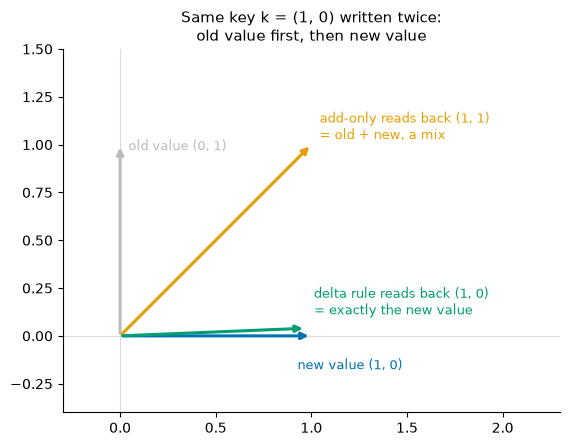

In [13]:
draw_delta_vs_add()

**그림에서 볼 것**: 주황 화살표(더하기만)는 $(1, 1)$, 즉 옛 값과 새 값의 **합**입니다. 방향은 둘의 한가운데이고 길이는 더 깁니다.
초록 화살표(delta rule)는 새 값(파랑)과 겹칩니다(겹쳐 보이게 살짝 띄워 그렸습니다).

**실험.** $N$ 개 쌍을 쓴 뒤, 같은 이름표에 새 내용을 한 번 더 씁니다. 그리고 이름표로 찾았을 때 **새 내용**이 나오는지 봅니다.

,pairs N,state,returns NEW value,cos to new,cos to old
0,16,linear (add only),0.31,0.63,0.65
1,16,delta rule,1.00,0.89,0.07
2,32,linear (add only),0.38,0.59,0.60
3,32,delta rule,1.00,0.81,0.10
4,48,linear (add only),0.48,0.55,0.55
5,48,delta rule,0.96,0.72,0.10


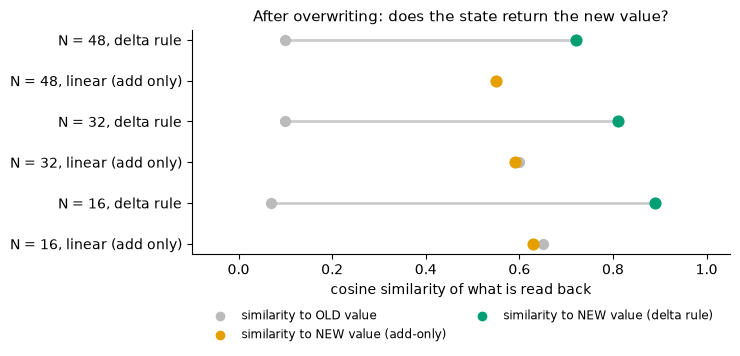

In [14]:
rows = []
for N in [16, 32, 48]:
    K, V_old = make_pairs(N, seed=1)
    _, V_new = make_pairs(N, seed=2)
    seqK, seqV = torch.cat([K, K]), torch.cat([V_old, V_new])      # 같은 이름표를 두 번 쓴다
    both = torch.cat([V_old, V_new])
    for name, S in [("linear (add only)", write_linear(seqK, seqV)), ("delta rule", write_delta(seqK, seqV))]:
        R = (S @ K.T).T
        got_new = ((F.normalize(R, dim=-1) @ both.T).argmax(-1) == torch.arange(N) + N).float().mean().item()
        rows.append({"pairs N": N, "state": name, "returns NEW value": round(got_new, 2),
                     "cos to new": round(F.cosine_similarity(R, V_new).mean().item(), 2),
                     "cos to old": round(F.cosine_similarity(R, V_old).mean().item(), 2)})
upd = pd.DataFrame(rows)
display(upd)

lin = upd[upd.state == "linear (add only)"]
dlt = upd[upd.state == "delta rule"]
assert (dlt["returns NEW value"].values > 0.9).all()
assert (lin["returns NEW value"].values < 0.7).all()         # 더하기만 하면 옛 값과 새 값이 섞여 반반
draw_update_results(upd)

**그림에서 볼 것**: 줄마다 회색 점은 옛 값과의 비슷함, 색 점은 새 값과의 비슷함입니다.
더하기만 하는 상태(주황)는 두 점이 비슷한 자리에 있어 옛 값과 새 값이 섞였고, delta rule(초록)은 새 값 쪽이 훨씬 오른쪽입니다.
숫자는 이 노트북의 장난감 실험 결과입니다. 이 실험은 $N \le 48$ 로 $d = 64$ 보다 작아서, delta rule 의 용량 한계는 시험하지 않았습니다.
상태 크기가 고정되어 있는 한, 갱신 규칙을 무엇으로 하든 찾기 성능에는 천장이 있다는 지적이 있습니다 [7].

## 4. 그래서 실제 모델은 섞어 쓴다 (hybrid, 슬라이드 86–91쪽 [1])

**한 줄 정의**: 층 대부분은 linear(또는 delta rule) 어텐션으로 싸게 돌리고, 일부 층만 전체 softmax 어텐션(또는 가까운 토큰만 보는 sliding-window 어텐션)을 두는 구조입니다.

**왜 필요한가**: 고정 크기 상태는 정확히 찾아오는 능력에 천장이 있습니다 [7]. 정확한 찾기는 소수의 전체 어텐션 층에 맡기고, 대부분의 층은 싸게 계산합니다.

**숫자로 따라가기**: Yang 등은 두 가지 hybrid 를 시험했습니다. (1) 한 층 걸러 sliding-window 어텐션, (2) 전체 어텐션 층 두 개를 넣은 것이며, 둘 다 강한 트랜스포머 기준 모델보다 나았다고 보고했습니다 [6].

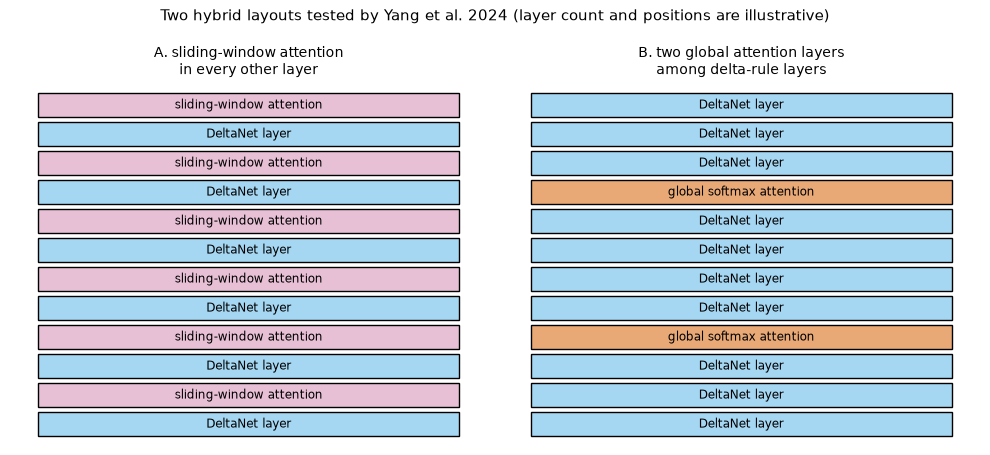

In [15]:
draw_hybrid_stack()

**그림에서 볼 것**: 하늘색이 delta rule 층, 보라가 sliding-window 어텐션, 빨강이 전체 softmax 어텐션입니다. 층 수와 위치는 설명용이고, 두 배치 방식만 [6] 을 따릅니다.

어느 쪽을 쓸지 고를 때 던질 질문 세 가지로 이 노트북을 다시 정리하면 이렇습니다(슬라이드 87쪽이 같은 비교를 다룹니다 [1]).

- **글이 두 배로 길어지면 계산은?** softmax 는 약 네 배(1-1), linear 는 약 두 배입니다(2-2).
- **글을 쓰는 동안 무엇을 들고 있어야 하나?** softmax 는 읽은 토큰 수만큼 쌓이는 Key·Value, linear 는 크기가 정해진 상태 하나입니다(2-2 그림).
- **오래전에 나온 정보를 콕 집어 찾아야 하나?** softmax 는 모든 토큰을 다시 볼 수 있어 유리하고, linear 는 눌러 담은 상태에서 꺼내야 해서 항목이 많으면 섞입니다(3-1).

에이전트 입장에서 이것이 중요한 이유: 에이전트는 아주 긴 문맥을 다루고, 추론 효율이 설계의 고려 사항이며,
모델 구조를 알아야 목적에 맞는 모델을 고르고 그 장단점에 맞춰 주변 장치를 만들 수 있습니다 [1, 91쪽].

## 연습 문제

1. `linear_attn_cumsum` 은 위치마다 $d \times d$ 상태를 저장합니다. 길이 $T$ 에서 메모리는 숫자 몇 개인가요? softmax 의 $T \times T$ 와 비교하면 언제 더 작은가요?
2. 용량 실험에서 차원 $d$ 를 128 로 늘리면 linear 기억의 그래프가 어떻게 바뀔까요?
3. delta rule 에서 $\beta = 0$ 이면? $\beta = 1$ 이고 이름표가 단위 벡터면, 쓰자마자 그 이름표로 찾을 때 무엇이 나오나요?
4. 1-1 그림에서 $d = 128$ 이면 두 곡선은 어디서 만날까요?

<details><summary>답 보기</summary>

1. $T \cdot d^2$ 개입니다. $T^2$ 보다 작으려면 $T > d^2$, 즉 $d = 64$ 이면 $T > 4{,}096$ 일 때입니다. 그래서 실제 구현은 덩어리(chunk) 단위로 계산해 이 메모리를 줄입니다 [6].
2. 무너지기 시작하는 지점이 대략 두 배 뒤로 밀립니다. 서로 직각인 방향이 $d$ 개까지 있으므로 담을 수 있는 쌍의 수가 $d$ 에 비례하기 때문입니다.
   (이 노트북 작성 때 같은 코드로 확인한 값: $d = 64$ 는 $N$ = 256 에서 0.77, $d = 128$ 은 $N$ = 256 에서 1.00, $N$ = 512 에서 0.98.)
3. $\beta = 0$ 이면 아무것도 쓰지 않습니다. $\beta = 1$ 이면 $S k_t = S_{old} k_t + (v_t - S_{old} k_t)(k_t \cdot k_t) = v_t$ 이므로 방금 쓴 값이 정확히 나옵니다.
4. $n^2 d = 2 n d^2$ 에서 $n = 2d = 256$ 입니다.
</details>

## 정리

- softmax 어텐션은 모든 앞 토큰과 점수를 매겨 $O(n^2)$ 이고, 글을 쓸 때 앞 토큰 전부의 Key, Value 를 들고 있어야 합니다.
- linear attention 은 $\exp(q \cdot k)$ 를 $\phi(q) \cdot \phi(k)$ 로 바꿔, 같은 계산을 "고정 크기 상태를 갱신하는 RNN"으로 다시 씁니다. 비용은 길이에 비례합니다.
- 대가: $d \times d$ 상태 하나에 모든 것을 눌러 담아, 쌍이 많아지면 섞입니다. delta rule 은 덮어쓰기를 가능하게 하고, 실제 모델은 전체 어텐션 층과 섞어서 약점을 메웁니다.

## 실제와 다른 점

- 3절 실험은 원리를 보려고 $\phi$ 와 정규화(나누기)를 뺀 순수 연상 기억입니다. 실제 linear attention 층은 학습된 $W_Q, W_K, W_V$ 와 $\phi$ 를 거칩니다.
- 1-1 의 곱셈 수는 어림이고, 2-2 의 시간은 이 노트북을 실행한 기계의 값입니다.
- hybrid 그림의 층 수와 위치는 설명용입니다.

## 출처

| 번호 | 출처 | 이 노트북에서 쓴 곳 |
|---|---|---|
| [1] | Yang, Ryan, Yang. CS329Z Lecture 2 "LLMs for Builders" 슬라이드 (Stanford, 2026). [PDF](https://web.stanford.edu/class/cs329z/slides/lecture02.pdf), 사본 `data/lecture02.pdf` | 25쪽 언어 모델 구조의 역사(RNN), 61–62쪽 어텐션과 순환 비교, 66–67쪽 softmax 를 빼고 곱하는 순서 바꾸기, 68–82쪽 상태 갱신과 갱신 규칙(필요 없는 기억 지우기), 83쪽 속도·메모리, 84쪽 긴 글에서의 어려움(RULER 그림), 86–90쪽 hybrid, 87쪽 두 어텐션 비교, 91쪽 에이전트에 중요한 이유 |
| [2] | Michael Ryan. Stanford CS329Z Lecture 2 영상 (Stanford Online, 2026). [YouTube](https://www.youtube.com/watch?v=Vr1NzH8bT44) | 영상 구간 28:27 ~ 36:01 |
| [3] | Vaswani 등. Attention Is All You Need. NeurIPS 2017. [arXiv:1706.03762](https://arxiv.org/abs/1706.03762) | 표 1: 층별 계산량 $O(n^2 d)$ 대 $O(n d^2)$, 순서대로 할 단계 수 $O(1)$ 대 $O(n)$ |
| [4] | Katharopoulos, Vyas, Pappas, Fleuret. Transformers are RNNs: Fast Autoregressive Transformers with Linear Attention. ICML 2020. [arXiv:2006.16236](https://arxiv.org/abs/2006.16236) (사본 `data/`) | 식 (7) $\phi(x) = \text{elu}(x) + 1$, RNN 꼴과 일정한 메모리, 누적합 계산, 최대 4,000배 빠른 이어 쓰기 |
| [5] | Schlag, Irie, Schmidhuber. Linear Transformers Are Secretly Fast Weight Programmers. ICML 2021, PMLR 139: 9355–9366. [arXiv:2102.11174](https://arxiv.org/abs/2102.11174) | linear attention 기억 용량의 한계, 순수 덧셈 대신 delta rule 같은 갱신 |
| [6] | Yang, Wang, Zhang, Shen, Kim. Parallelizing Linear Transformers with the Delta Rule over Sequence Length. NeurIPS 2024. [arXiv:2406.06484](https://arxiv.org/abs/2406.06484) | DeltaNet 의 delta(Widrow-Hoff) 갱신식, 덩어리(chunkwise) 병렬 계산, linear attention 이 문맥 안 찾기에서 뒤처짐, 두 가지 hybrid 실험 |
| [7] | Songlin Yang. DeltaNet Explained (Part III) 블로그 (2024). [링크](https://sustcsonglin.github.io/blog/2024/deltanet-3/) (슬라이드 63·86·88쪽이 그림을 인용) | 고정 크기 상태는 갱신 규칙과 상관없이 찾기 성능에 천장을 만든다, sliding-window·global 어텐션과 섞는 hybrid |
| [8] | Hsieh 등. RULER: What's the Real Context Size of Your Long-Context Language Models? COLM 2024. [arXiv:2404.06654](https://arxiv.org/abs/2404.06654) (슬라이드 84쪽이 그림 4를 인용) | 그림 4 구조 비교(Llama2-7B, RWKV-v5-7B, Mamba-2.8B, 1K–8K), 비트랜스포머 구조가 트랜스포머보다 크게 뒤처진다 |

시간, 기억 용량, 덮어쓰기 실험의 숫자는 출처가 아니라 이 노트북에서 직접 계산한 값입니다.